# CGLS: least-squares reconstruction of a Lu-177 patient

OSEM maximises the Poisson likelihood of the data and keeps every voxel non-negative. CGLS, conjugate gradients for
least squares, minimises the squared difference between the measured and the predicted projections,
$\frac{1}{2}\|Hf + s - g\|^2$, with no constraint on the sign of the image: it runs conjugate gradients on the normal
equations $H^T H f = H^T (g - s)$, at one forward and one back projection per iteration, without ever forming
$H^T H$. Three things follow, and this tutorial shows each on the two-bed Lu-177 PSMA patient of the
[multiple bed positions](t_dicommultibed.ipynb) tutorial:

- CGLS needs the back projector to be the exact transpose of the forward projector.
- As it converges, it fits the noise: the number of iterations is the regularizer.
- Its images keep negative values, which least squares allows.

CGLS (`pytomography.algorithms.CGLS`) was contributed by Hoyant-Su.

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("SPECT/Lu177-PSMA-GEDisc")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("SPECT/Lu177-PSMA-GEDisc")

SPECT/Lu177-PSMA-GEDisc: already downloaded


In [2]:
import os
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
import pytomography
from pytomography import io
from pytomography.utils import plot_utils
from pytomography.transforms.SPECT import SPECTAttenuationTransform, SPECTPSFTransform
from pytomography.projectors.SPECT import SPECTSystemMatrix
from pytomography.likelihoods import NegativeMSELikelihood, PoissonLogLikelihood
from pytomography.algorithms import CGLS, OSEM

In [3]:
# Memory: each bed is 128 x 128 x 128 voxels and 60 views, so a reconstruction needs about 0.5 GB of GPU memory and the
# tutorial peaks at about 6 GB of RAM (measured on Windows); nothing here grows with RAM_GB. CGLS holds four images and
# two sets of projections per bed while it runs.
RAM_GB = 25
pytomography.set_memory_budget(RAM_GB)

## 1. The patient

Two bed positions of a GE Discovery 670 scan, at Lu-177's 208 keV photopeak (window 1), with the scatter estimated
from the two neighbouring windows (triple energy window), and a system matrix for each bed with attenuation from the
CT and the collimator's Gaussian PSF. The [multiple bed positions](t_dicommultibed.ipynb) tutorial goes through each
of these steps; here they are in one cell.

In [4]:
path = DATA / 'SPECT' / 'Lu177-PSMA-GEDisc'
files_NM = [str(path / 'bed1_projections.dcm'), str(path / 'bed2_projections.dcm')]
files_CT = [str(path / 'CT' / f) for f in os.listdir(path / 'CT')]
file_RT = str(path / 'segmentations.dcm')  # organs drawn on the CT (RTSTRUCT)

beds = []
for projections, object_meta, proj_meta in io.SPECT.read_dicom_beds(files_NM):  # the inferior bed first
    energy = proj_meta.energy_windows[1].photon_energy
    attenuation_map = io.attenuation_map(files_CT, object_meta, energy=energy)
    psf = SPECTPSFTransform(io.SPECT.collimator_psf('GI-MEGP', energy))
    system_matrix = SPECTSystemMatrix([SPECTAttenuationTransform(attenuation_map), psf], [], object_meta, proj_meta)
    scatter = io.SPECT.energy_window_scatter(projections, proj_meta, 1, 3, 2)
    beds.append(dict(system_matrix=system_matrix, photopeak=projections[1], scatter=scatter, object_meta=object_meta))
print(f"{len(beds)} beds of {tuple(beds[0]['photopeak'].shape)} projections (views, r, z)")

2 beds of (60, 128, 128) projections (views, r, z)


## 2. CGLS needs an exact transpose

Conjugate gradients relies on $H^T$ being the transpose of $H$: for any image $x$ and projections $y$,
$\langle Hx, y\rangle = \langle x, H^T y\rangle$. PyTomography's SPECT back projector rotates the image by
interpolation, which is not always an exact transpose. On this scan the two sides agree to about one part in ten
million, so CGLS's guarantees hold:

In [5]:
H = beds[0]['system_matrix']
g = torch.Generator().manual_seed(0)
x = torch.rand(H.object_meta.shape, generator=g).to(pytomography.device)
y = torch.rand(beds[0]['photopeak'].shape, generator=g).to(pytomography.device)
mismatch = float((H.forward(x) * y).sum() / (x * H.backward(y)).sum() - 1)
print(f"<Hx, y> / <x, H^T y> - 1 = {mismatch:.1e}")

<Hx, y> / <x, H^T y> - 1 = 3.6e-07


## 3. OSEM, for comparison

Each bed is reconstructed on its own and the two are stitched (`io.SPECT.stitch_beds`). `reconstruct` does that for
any algorithm: `make` builds the algorithm for one bed, and the keyword arguments are what it runs with.

In [6]:
def reconstruct(make, **settings):
    """Reconstruct both beds with make(bed)(**settings), and stitch them; also return the algorithms."""
    algorithms = [make(bed) for bed in beds]
    t0 = time.time()
    recons = [algorithm(**settings) for algorithm in algorithms]
    seconds = time.time() - t0
    stitched, object_meta = io.SPECT.stitch_beds(recons=torch.stack(recons[::-1]),
                                                 object_metas=[bed['object_meta'] for bed in beds[::-1]])
    return stitched, object_meta, algorithms, seconds


osem, object_meta_stitched, _, seconds = reconstruct(
    lambda bed: OSEM(PoissonLogLikelihood(bed['system_matrix'], bed['photopeak'], additive_term=bed['scatter'])),
    n_iters=4, n_subsets=8)
print(f"OSEM, 4 iterations of 8 subsets: {seconds:.1f} s for both beds")

OSEM, 4 iterations of 8 subsets: 1.0 s for both beds


## 4. CGLS, and when to stop

`CGLS` takes the least-squares data (`NegativeMSELikelihood`, with the scatter as the additive term) and runs
`n_iters` iterations from a zero image. Each call starts its conjugate directions afresh, so the images after 5, 10, 20,
40 and 80 iterations come from separate runs. `rtol=0` keeps it from stopping early on its own criterion (the normal
residual falling by a factor of a million), which noisy data never reach in a useful number of iterations.

In [7]:
cgls, residuals = {}, {}
for n in (5, 10, 20, 40, 80):
    image, _, algorithms, seconds = reconstruct(
        lambda bed: CGLS(NegativeMSELikelihood(bed['system_matrix'], bed['photopeak'], additive_term=bed['scatter'])),
        n_iters=n, rtol=0)
    cgls[n] = image
    residuals['CGLS'] = algorithms[1].normal_residual_norms  # the upper bed
    print(f"CGLS, {n:2d} iterations: {seconds:4.1f} s for both beds")

CGLS,  5 iterations:  0.8 s for both beds


CGLS, 10 iterations:  1.4 s for both beds


CGLS, 20 iterations:  2.6 s for both beds


CGLS, 40 iterations:  5.0 s for both beds


CGLS, 80 iterations:  9.7 s for both beds


### A diagonal preconditioner

The image converges slowly where the system matrix is weak (deep in the body, at the edges of the field of view).
`preconditioner=` takes a positive diagonal $D$ and runs conjugate gradients on $D^{1/2} H^T H D^{1/2}$ instead, which
changes the path, not the least-squares solution. Here $D = 1 / (H^T H \mathbf{1})$, which costs one forward and one
back projection: not the exact diagonal of $H^T H$, but a common stand-in that scales each voxel by how strongly the
data constrain it.

In [8]:
def preconditioned(bed):
    H = bed['system_matrix']
    ones = torch.ones(H.object_meta.shape, device=pytomography.device)
    D = 1 / H.backward(H.forward(ones)).clamp(min=1e-6)
    return CGLS(NegativeMSELikelihood(H, bed['photopeak'], additive_term=bed['scatter']), preconditioner=D)


pcgls = {}
for n in (5, 10, 20):
    image, _, algorithms, seconds = reconstruct(preconditioned, n_iters=n, rtol=0)
    pcgls[n] = image
    residuals['Preconditioned CGLS'] = algorithms[1].normal_residual_norms
    print(f"Preconditioned CGLS, {n:2d} iterations: {seconds:4.1f} s for both beds")

Preconditioned CGLS,  5 iterations:  0.8 s for both beds


Preconditioned CGLS, 10 iterations:  1.4 s for both beds


Preconditioned CGLS, 20 iterations:  2.6 s for both beds


## 5. Bias and noise

The organs drawn on the CT (`segmentations.dcm`) go on the stitched grid with `io.load_mask`. For every image, the
mean in the kidneys (where the uptake is highest) shows how far the iterations have recovered the activity, and the
voxel-to-voxel spread in the liver (its coefficient of variation) shows the noise.

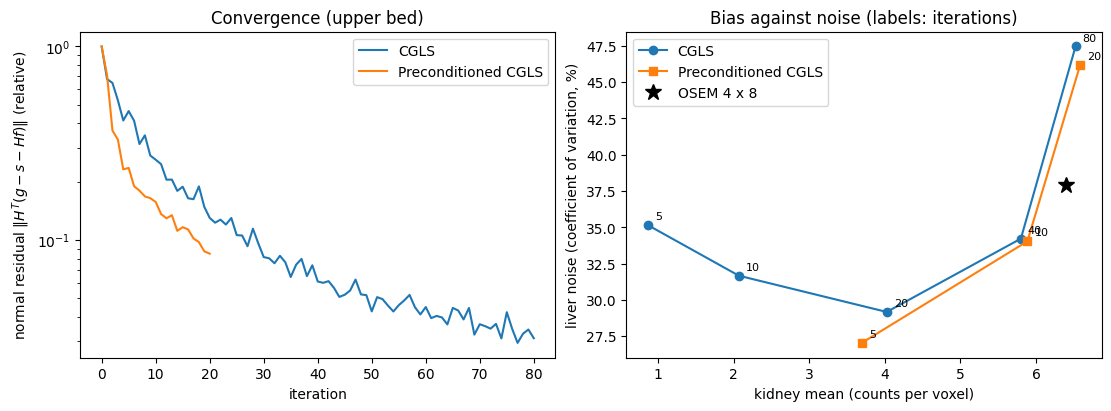

In [9]:
rois = ['liver', 'kidney_left', 'kidney_right', 'spleen']
masks = {roi: io.load_mask(file_RT, reference=str(path / 'CT'), rois=[roi]).on(object_meta_stitched, label=roi,
                                                                                 threshold=0.5).to(pytomography.device)
         for roi in rois}
kidneys = masks['kidney_left'] | masks['kidney_right']


def scores(image):
    liver = image[masks['liver']]
    return float(image[kidneys].mean()), float(100 * liver.std() / liver.mean())


fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for label_, r_ in residuals.items():
    axes[0].semilogy(np.arange(len(r_)), np.asarray(r_) / r_[0], label=label_)
axes[0].set(xlabel='iteration', ylabel='normal residual $\\|H^T(g - s - Hf)\\|$ (relative)',
            title='Convergence (upper bed)')
axes[0].legend()
for label_, runs_, marker_ in [('CGLS', cgls, 'o-'), ('Preconditioned CGLS', pcgls, 's-')]:
    kid_, cv_ = zip(*[scores(runs_[it_]) for it_ in runs_])
    axes[1].plot(kid_, cv_, marker_, label=label_)
    for it_, x_, y_ in zip(runs_, kid_, cv_):
        axes[1].annotate(f'{it_}', (x_, y_), textcoords='offset points', xytext=(5, 4), fontsize=8)
kid_, cv_ = scores(osem)
axes[1].plot(kid_, cv_, 'k*', ms=12, label='OSEM 4 x 8')
axes[1].set(xlabel='kidney mean (counts per voxel)', ylabel='liver noise (coefficient of variation, %)',
            title='Bias against noise (labels: iterations)')
axes[1].legend()
plt.show()

The normal residual falls faster with the preconditioner, and 10 preconditioned iterations reach about where 40 plain
ones do. On the right, the first iterations recover the kidneys' activity while the noise falls (the image is still
smooth); after that each iteration buys less activity for more noise: from 40 to 80 iterations the kidney mean rises
by another 12% while the liver's noise grows from 34% to 47%. Where to stop is the choice that regularizes the image.
The images show the same:

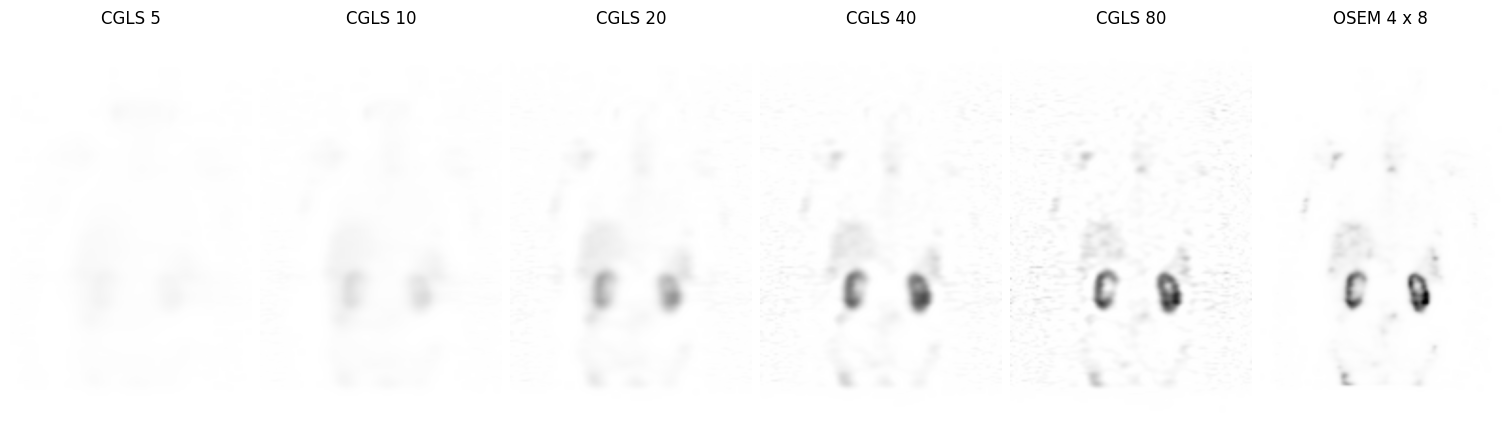

In [10]:
j = int(kidneys.nonzero()[:, 1].float().mean())  # the coronal slice through the kidneys
shown = {f'CGLS {n}': cgls[n] for n in (5, 10, 20, 40, 80)} | {'OSEM 4 x 8': osem}
vmax = float(osem[kidneys].quantile(0.99))
fig, axes = plt.subplots(1, len(shown), figsize=(15, 5.2), constrained_layout=True)
for ax, (title_, img_) in zip(axes, shown.items()):
    ax.imshow(img_[:, j].cpu().T, cmap='Greys', vmin=0, vmax=vmax, origin='lower', interpolation='gaussian',
              aspect=object_meta_stitched.dr[2] / object_meta_stitched.dr[0])
    ax.set_title(title_)
    ax.axis('off')
plt.show()

## 6. Negative values

Least squares has no reason to keep an image positive: where there is little activity, noise pushes about as many
voxels below zero as above. OSEM's multiplicative update can't go below zero, so in those regions its noise only adds:
its total counts are higher than CGLS's.

OSEM 4 x 8               negative voxels in the body:  0.0%   total:    197884 counts
CGLS 40                  negative voxels in the body: 37.4%   total:    177386 counts
Preconditioned CGLS 10   negative voxels in the body: 37.2%   total:    178505 counts


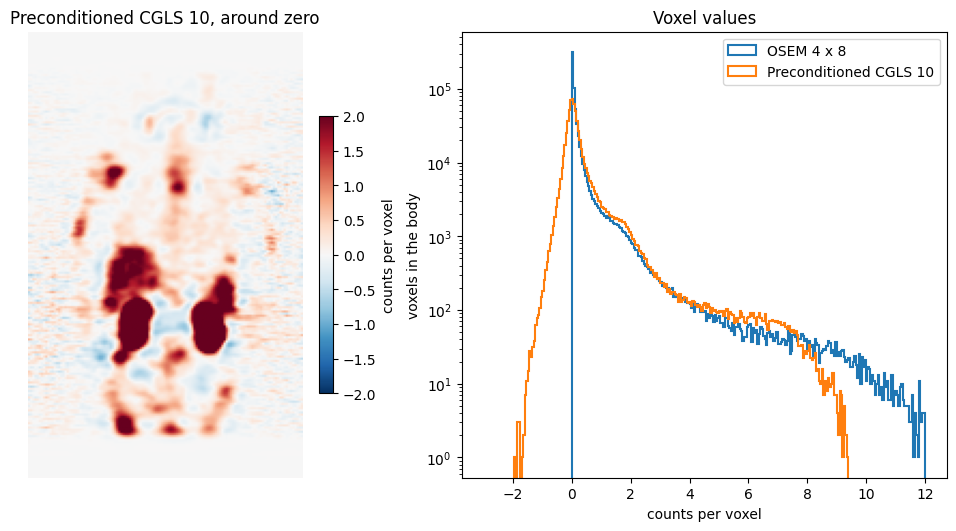

In [11]:
body = io.attenuation_map(files_CT, object_meta_stitched, energy=208.0).to(pytomography.device) > 0.005
chosen = pcgls[10]  # preconditioned CGLS, 10 iterations: about CGLS's 40
for name, image in [('OSEM 4 x 8', osem), ('CGLS 40', cgls[40]), ('Preconditioned CGLS 10', chosen)]:
    print(f"{name:24s} negative voxels in the body: {100 * float((image[body] < 0).float().mean()):4.1f}%   "
          f"total: {float(image.sum()):9.0f} counts")

fig, axes = plt.subplots(1, 2, figsize=(10, 5.2), constrained_layout=True,
                         gridspec_kw={'width_ratios': [1, 1.4]})
im = axes[0].imshow(chosen[:, j].cpu().T, cmap='RdBu_r', vmin=-2, vmax=2, origin='lower',
                    aspect=object_meta_stitched.dr[2] / object_meta_stitched.dr[0])
axes[0].set_title('Preconditioned CGLS 10, around zero')
axes[0].axis('off')
fig.colorbar(im, ax=axes[0], fraction=0.04, label='counts per voxel')
bins = np.linspace(-3, 12, 301)
for title_, img_ in [('OSEM 4 x 8', osem), ('Preconditioned CGLS 10', chosen)]:
    axes[1].hist(img_[body].cpu().numpy(), bins=bins, histtype='step', lw=1.5, label=title_)
axes[1].set(yscale='log', xlabel='counts per voxel', ylabel='voxels in the body', title='Voxel values')
axes[1].legend()
plt.show()

## 7. OSEM and CGLS side by side

The preconditioned CGLS image after 10 iterations beside OSEM, both over the CT: a coronal slice through the kidneys
and an axial slice through them.

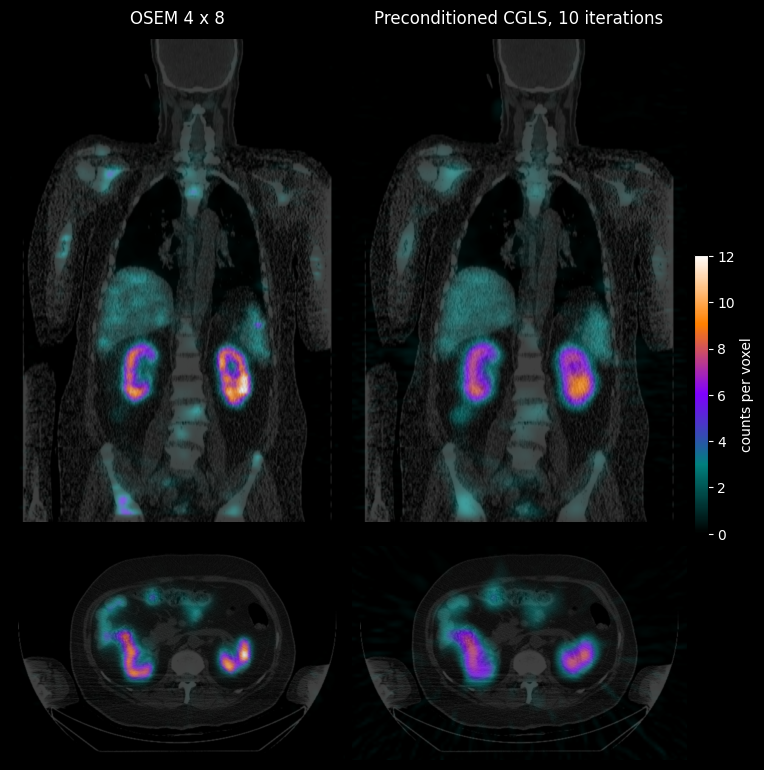

In [12]:
ct = io.load_image(files_CT)
k = int(kidneys.nonzero()[:, 2].float().mean())  # the axial slice through the kidneys
A = np.asarray(object_meta_stitched.affine)
nz = body.nonzero().cpu()
box = [sorted(A[a, a] * float(i) + A[a, 3] for i in (nz[:, a].min() - 3, nz[:, a].max() + 3)) for a in range(3)]  # mm
spect_kwargs = {'cmap': plot_utils.pet_cmap, 'interpolation': 'gaussian', 'vmin': 0, 'vmax': vmax, 'zorder': 1,
                'alpha': 0.75}
ct_kwargs = {'cmap': 'Greys_r', 'interpolation': 'gaussian', 'vmin': -200, 'vmax': 300, 'zorder': 0}  # HU
height = [box[2][1] - box[2][0], box[1][1] - box[1][0]]  # coronal: z; axial: y
fig, axes = plt.subplots(2, 2, figsize=(9, 9 * sum(height) / (2 * (box[0][1] - box[0][0]))), facecolor='k',
                         gridspec_kw={'height_ratios': height, 'wspace': 0.02, 'hspace': 0.02})
for col, (title_, img_) in enumerate([('OSEM 4 x 8', osem), ('Preconditioned CGLS, 10 iterations', chosen)]):
    img_ = img_.clamp(min=0)
    plt.sca(axes[0, col])
    plot_utils.dual_imshow_coronal(img_, ct.data, j, object_meta_stitched.affine, ct.affine, spect_kwargs, ct_kwargs)
    axes[0, col].set(xlim=box[0], ylim=box[2])
    axes[0, col].set_title(title_, color='white')
    plt.sca(axes[1, col])
    plot_utils.dual_imshow_axial(img_, ct.data, k, object_meta_stitched.affine, ct.affine, spect_kwargs, ct_kwargs)
    axes[1, col].set(xlim=box[0], ylim=box[1][::-1])  # anterior at the top
for ax in axes.flat:
    ax.axis('off')
bar = fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(0, vmax), plot_utils.pet_cmap), ax=axes, fraction=0.02,
                   pad=0.01)
bar.set_label('counts per voxel', color='white')
bar.ax.tick_params(colors='white')
plt.show()

In [13]:
print(f"{'':26s}" + ''.join(f'{roi:>14s}' for roi in rois) + f"{'liver noise':>14s}")
for name, image in [('OSEM 4 x 8', osem), ('CGLS 20', cgls[20]), ('CGLS 40', cgls[40]),
                    ('Preconditioned CGLS 10', chosen)]:
    means = ''.join(f'{float(image[masks[roi]].mean()):14.2f}' for roi in rois)
    print(f"{name:26s}{means}{scores(image)[1]:13.0f}%")

                                   liver   kidney_left  kidney_right        spleen   liver noise
OSEM 4 x 8                          1.46          6.39          6.41          1.82           38%
CGLS 20                             1.41          3.93          4.11          1.56           29%
CGLS 40                             1.48          5.81          5.80          1.80           34%
Preconditioned CGLS 10              1.50          5.85          5.92          1.86           34%


In the liver and spleen the two agree within 3%, and CGLS's liver is a little less noisy (34% against 38%). The
kidneys, small and bright, are 8% lower after 10 preconditioned iterations and reach OSEM's values by 20 (or 80 plain),
with more noise. CGLS gets there with no subsets and no positivity constraint, at the cost of negative voxels in the
background and an iteration count to choose.

## Save the images

`io.save_dicom` writes the CGLS image as a DICOM NM file in its place in the patient. NM images are stored as
non-negative integers, so the negative voxels are clipped to zero first (`clamp`); the full image is in `chosen`.

In [14]:
saved = io.save_dicom(chosen.clamp(min=0), OUTPUT / 't_cgls' / 'pcgls_10', object_meta_stitched,
                      reference=files_NM[1], series_description='Preconditioned CGLS 10, two beds stitched',
                      overwrite=True)

## Next steps

- [Reconstruction algorithms](t_algorithms.ipynb) compares OSEM with the penalised algorithms (BSREM, OSMAPOSL) and
  KEM on simulated data, where the truth is known.
- CGLS works with any system matrix whose back projection is its transpose: PET, CT and the others; check the
  transpose first, as in section 2.